<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/05-decision-trees/ML_lab5_decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Перші 5 рядків датасету:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0   

Загальна інформація про типи та пропуски
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    f

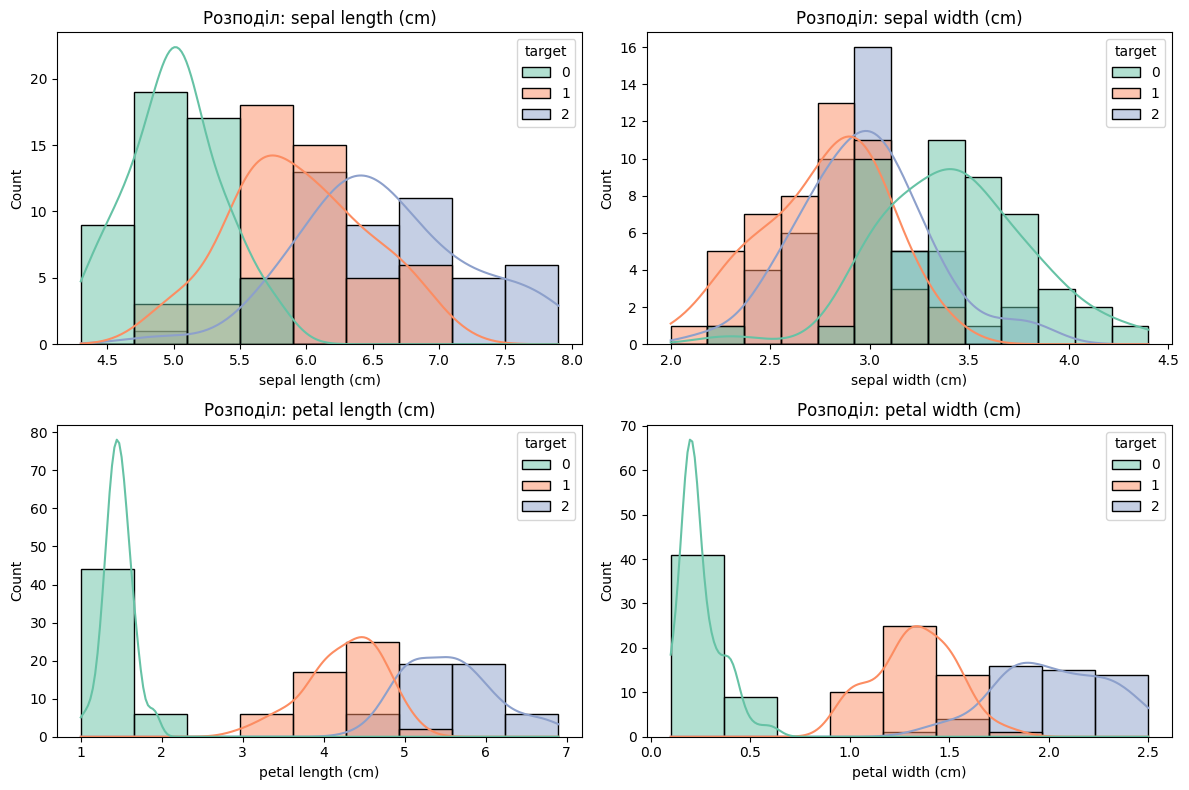

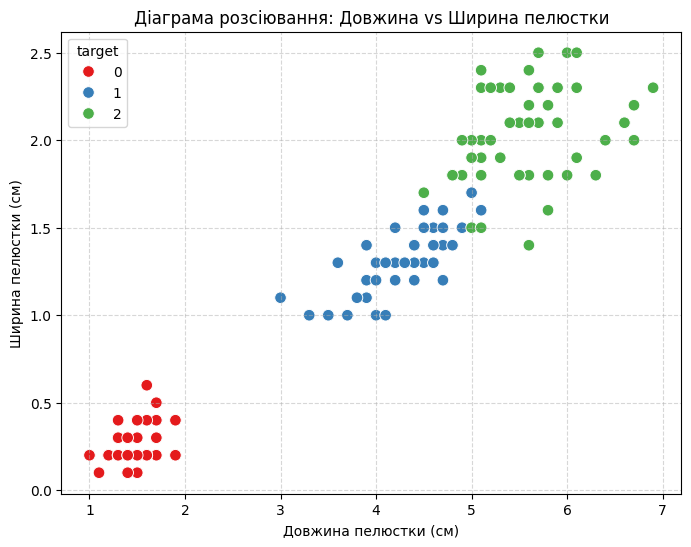

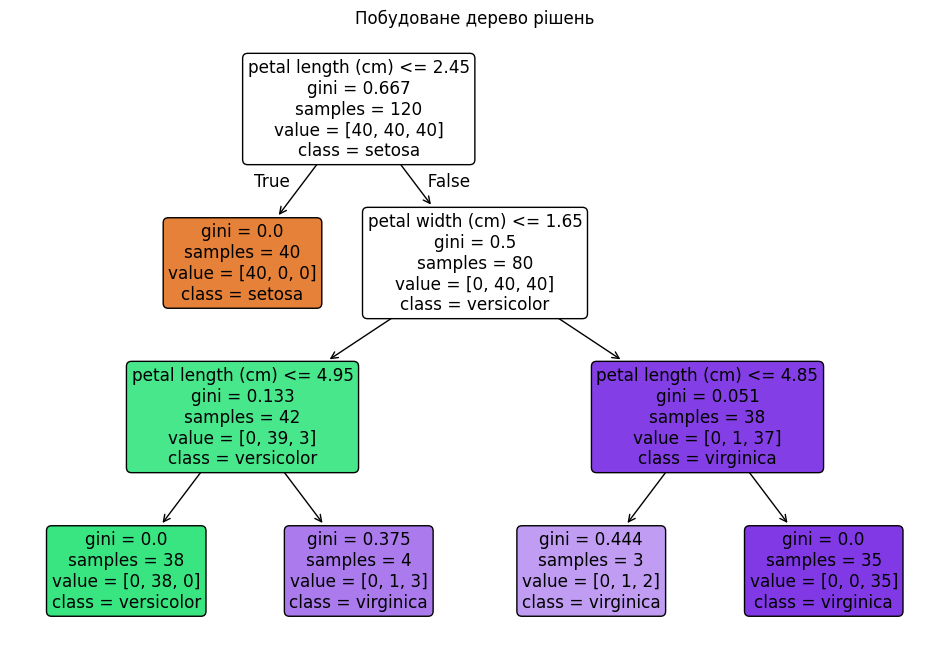

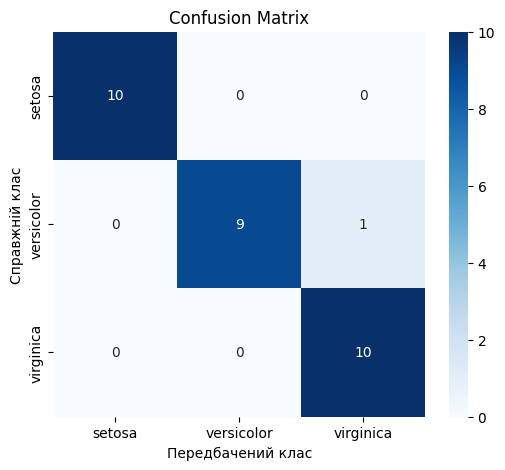

Метрики якості на тестовій вибірці
Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1 Score:  0.9666

Детальний Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Результати 5-Fold Крос-валідації
Оцінки Accuracy за фолдами: [0.9667 0.9667 0.9333 1.     0.9333]
Середня точність (Mean Accuracy): 0.9600
Стандартне відхилення: 0.0249


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree



iris = load_iris(as_frame=True)
df = iris.frame

print("Перші 5 рядків датасету:")
print(df.head(), "\n")

print("Загальна інформація про типи та пропуски")
df.info()
print("\nОписові статистики (розподіли, квартилі)")
print(df.describe(), "\n")

print("Розподіл за класами")
print(df["target"].value_counts(), "\n")


# 2. Візуалізація даних
feature_names = iris.feature_names

# 2.1 Гістограми розподілу для кожної ознаки
plt.figure(figsize=(12, 8))
for i, feature in enumerate(feature_names, 1): #1 + sepal length
    plt.subplot(2, 2, i) #2сітка2 за і
    sns.histplot(data=df, x=feature, hue="target", kde=True, palette="Set2")
    #крива, кожна палка окремо,
    plt.title(f"Розподіл: {feature}")
plt.tight_layout()
plt.show()

# 2.2 Точкова діаграма (Scatter Plot) для ознак пелюстки
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="target",
    palette="Set1",
    s=70,
)
plt.title("Діаграма розсіювання: Довжина vs Ширина пелюстки")
plt.xlabel("Довжина пелюстки (см)")
plt.ylabel("Ширина пелюстки (см)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


# 3. Підготовка даних та навчання дерева
X = df[feature_names]
y = df["target"]

# 80/20, щоб зберегти баланс класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# max_depth=3 для запобігання перенавчанню
clf = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
clf.fit(X_train, y_train)

# Візуалізація структури отриманого дерева
plt.figure(figsize=(12, 8))
plot_tree(
    clf,
    feature_names=feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
)
plt.title("Побудоване дерево рішень")
plt.show()


# 4. Оцінка моделі: Матриця помилок та метрики
y_pred = clf.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
)
plt.title("Confusion Matrix")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.show()

# Розрахунок метрик
print("Метрики якості на тестовій вибірці")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred, average='macro'):.4f}\n")

print("Детальний Classification Report")
print(classification_report(y_test, y_pred, target_names=iris.target_names))



cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")

print("Результати 5-Fold Крос-валідації")
print(f"Оцінки Accuracy: {np.round(cv_scores, 4)}")
print(f"Середня точність (Mean Accuracy): {cv_scores.mean():.4f}")
print(f"Стандартне відхилення: {cv_scores.std():.4f}")

Перші 5 рядків датасету
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2   

Інформація про наявність пропусків та типи даних
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-nul

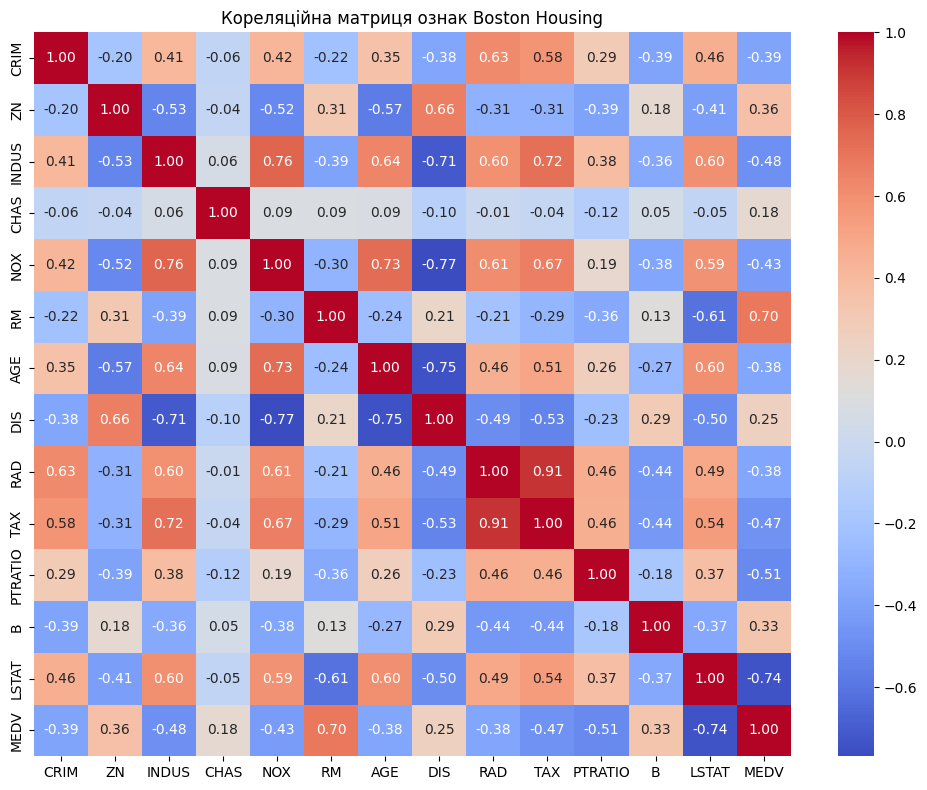

Розмір навчальної вибірки: 404 рядків
Розмір тестової вибірки: 102 рядків



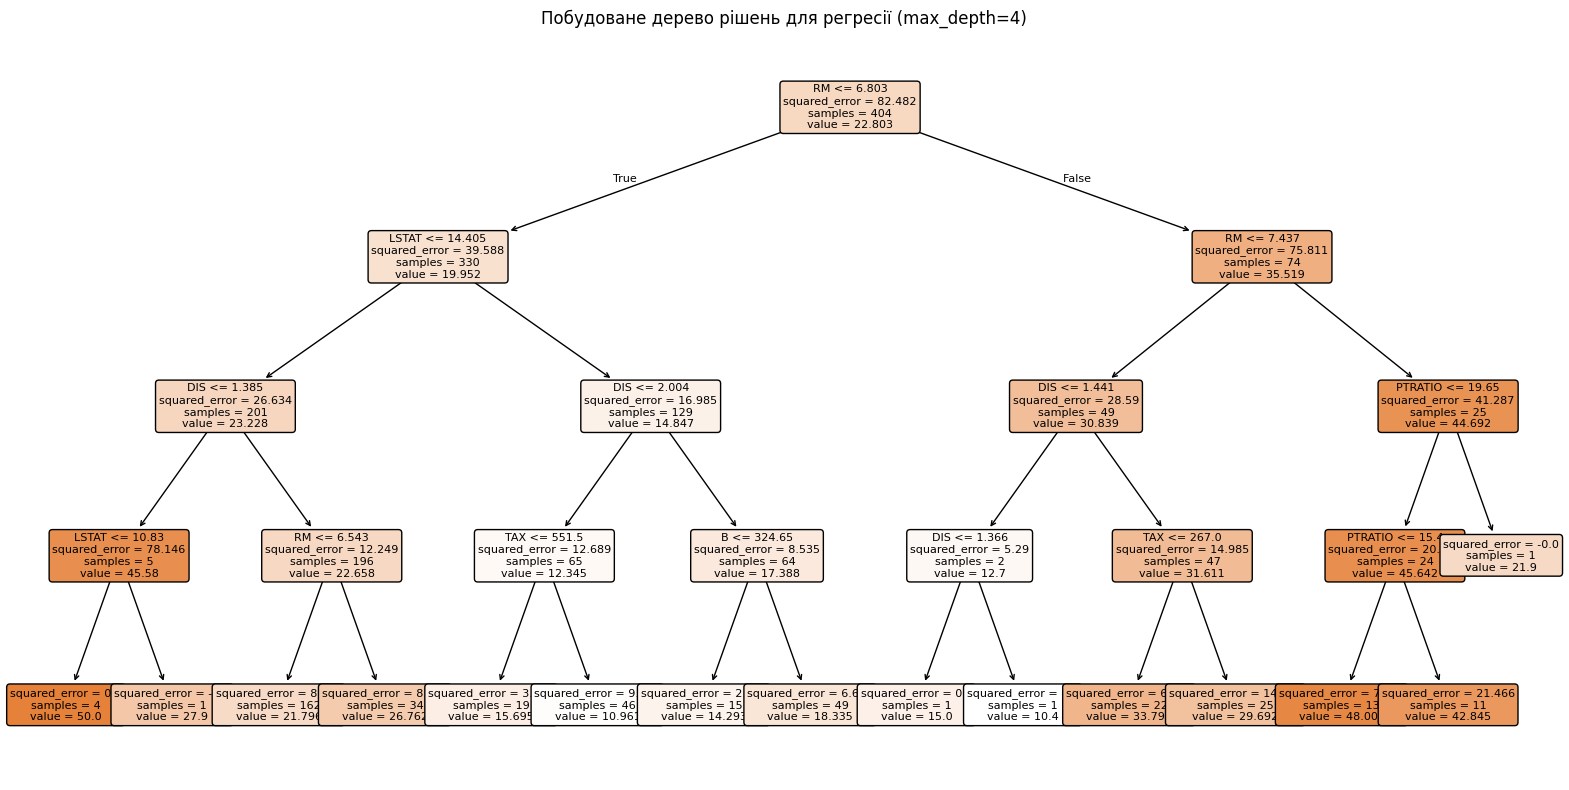

      Метрика  Лінійна регресія (OLS)  Дерево регресії (CART)
          MAE                3.626784                3.589474
          MSE               24.318238               32.448897
         RMSE                4.931353                5.696393
R² (на тесті)                0.731767                0.642084
 R² (CV mean)                0.353276                0.179001


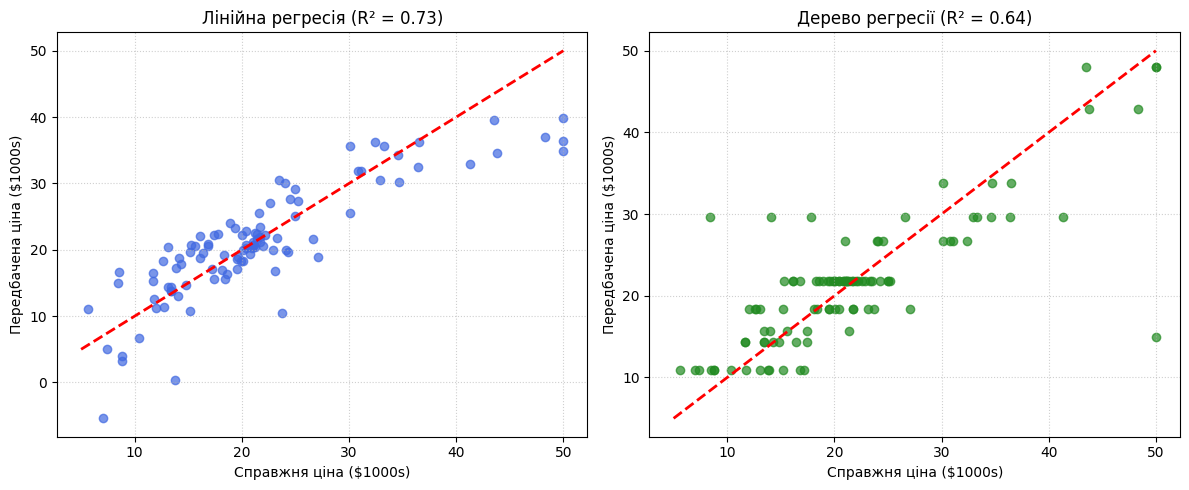

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree


# Завантаження набору Boston Housing через URL
data_url = "http://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
                      #кожний 2 рядок з 1           А тут непарні, з 1 рядка кожен 2 рядок та 2 колонки
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])

target = raw_df.values[1::2, 2]
#рядки 1 3 5...  , 2 - тільки 2 колонка


feature_names = [
    "CRIM",
    "ZN",
    "INDUS",
    "CHAS",
    "NOX",
    "RM",
    "AGE",
    "DIS",
    "RAD",
    "TAX",
    "PTRATIO",
    "B",
    "LSTAT",
]

df = pd.DataFrame(data, columns=feature_names)
df["MEDV"] = target  #медіанна вартість житла (цільова змінна)

print("Перші 5 рядків датасету")
print(df.head(), "\n")

print("Інформація про наявність пропусків та типи даних")
df.info()

print("\nОписові статистики (розподіли, квантилі, середнє)")
print(df.describe(), "\n")

# кореляційна матриця для виявлення зв'язків з ціною (MEDV)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Кореляційна матриця ознак Boston Housing")
plt.tight_layout()
plt.show()


X = df.drop(columns=["MEDV"])
y = df["MEDV"]

# Розділення 80% на навчання, 20% на тестування
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=13
)
print(f"Розмір навчальної вибірки: {X_train.shape[0]} рядків")
print(f"Розмір тестової вибірки: {X_test.shape[0]} рядків\n")


# 3. Лінійна регресійна модель
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred_lin = lin_reg.predict(X_test)


# 4. Нелінійна регресійна модель (DecisionTreeRegressor)
# Обмежуємо max_depth=4 для запобігання перенавчанню
tree_reg = DecisionTreeRegressor(max_depth=4, random_state=13)
tree_reg.fit(X_train, y_train)

y_pred_tree = tree_reg.predict(X_test)

# Візуалізація отриманого дерева регресії
plt.figure(figsize=(16, 8))
plot_tree(
    tree_reg,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Побудоване дерево рішень для регресії (max_depth=4)")
plt.tight_layout()
plt.show()


# Крос-валідація для обох моделей
# У scikit-learn метрики помилки максимізуються, тому вони йдуть зі знаком мінус: 'neg_root_mean_squared_error'
lin_cv_rmse = -cross_val_score(
    lin_reg, X, y, cv=5, scoring="neg_root_mean_squared_error"
)
tree_cv_rmse = -cross_val_score(
    tree_reg, X, y, cv=5, scoring="neg_root_mean_squared_error"
)

lin_cv_r2 = cross_val_score(lin_reg, X, y, cv=5, scoring="r2")
tree_cv_r2 = cross_val_score(tree_reg, X, y, cv=5, scoring="r2")


def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2


mae_lin, mse_lin, rmse_lin, r2_lin = calculate_metrics(y_test, y_pred_lin)
mae_tree, mse_tree, rmse_tree, r2_tree = calculate_metrics(y_test, y_pred_tree)

results = pd.DataFrame(
    {
        "Метрика": ["MAE", "MSE", "RMSE", "R² (на тесті)", "R² (CV mean)"],
        "Лінійна регресія (OLS)": [
            mae_lin,
            mse_lin,
            rmse_lin,
            r2_lin,
            lin_cv_r2.mean(),
        ],
        "Дерево регресії (CART)": [
            mae_tree,
            mse_tree,
            rmse_tree,
            r2_tree,
            tree_cv_r2.mean(),
        ],
    }
)


print(results.to_string(index=False))


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lin, color="royalblue", alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
plt.title(f"Лінійна регресія (R² = {r2_lin:.2f})")
plt.xlabel("Справжня ціна ($1000s)")
plt.ylabel("Передбачена ціна ($1000s)")
plt.grid(True, linestyle=":", alpha=0.6)

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_tree, color="forestgreen", alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
plt.title(f"Дерево регресії (R² = {r2_tree:.2f})")
plt.xlabel("Справжня ціна ($1000s)")
plt.ylabel("Передбачена ціна ($1000s)")
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()